In [1]:
from flow_models import get_depth_model

/root/miniconda3/envs/EndoFlow4/lib/python3.8/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
xFormers not available
xFormers not available


[!!alt_cuda_corr is not compiled!!]


xFormers not available
xFormers not available


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
depth_model = get_depth_model("foundation_stereo")

/root/miniconda3/envs/EndoFlow4/lib/python3.8/site-packages/torch/hub.py:295: UserWarning: You are about to download and run code from an untrusted repository. In a future release, this won't be allowed. To add the repository to your trusted list, change the command to {calling_fn}(..., trust_repo=False) and a command prompt will appear asking for an explicit confirmation of trust, or load(..., trust_repo=True), which will assume that the prompt is to be answered with 'yes'. You can also use load(..., trust_repo='check') which will only prompt for confirmation if the repo is not already trusted. This will eventually be the default behaviour
  warnings.warn(
Downloading: "https://github.com/nhphucqt/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
/root/.cache/torch/hub/nhphucqt_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/nhphucqt_dinov2_main/dinov2/layers/

In [7]:
from PIL import Image
import numpy as np
import torch

def load_image(path):
    image = np.array(Image.open(path)) / 255.0
    image = torch.from_numpy(image).permute(2, 0, 1).cuda().float()

    return image

left_path = "/network-volume/nhphuc/dataset/stereomis/p2_6_5000_200_s4/images_left/005000.png"
right_path = "/network-volume/nhphuc/dataset/stereomis/p2_6_5000_200_s4/images_right/005000.png"
intrinsic_path = "/network-volume/nhphuc/dataset/stereomis/p2_6_5000_200_s4/K.npy"

image_left = load_image(left_path)
image_right = load_image(right_path)
with open(intrinsic_path, "rb") as f:
    K = np.load(f)
    baseline = np.load(f)

fx = K[0, 0]

with torch.no_grad():
    depth = depth_model.forward(image_left, image_right, fx, baseline)


/network-volume/nhphuc/EndoFlow/thirdparty/FoundationStereo/FoundationStereo/core/foundation_stereo.py:206: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/network-volume/nhphuc/EndoFlow/thirdparty/FoundationStereo/FoundationStereo/core/../core/submodule.py:390: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/network-volume/nhphuc/EndoFlow/thirdparty/FoundationStereo/FoundationStereo/core/../core/geometry.py:73: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/network-volume/nhphuc/EndoFlow/thirdparty/FoundationStereo/FoundationStereo/core/foundation_stereo.py:245: FutureWarning: `torch.cuda.amp.autocast(args...)` is de

In [4]:
depth.shape

torch.Size([512, 640])

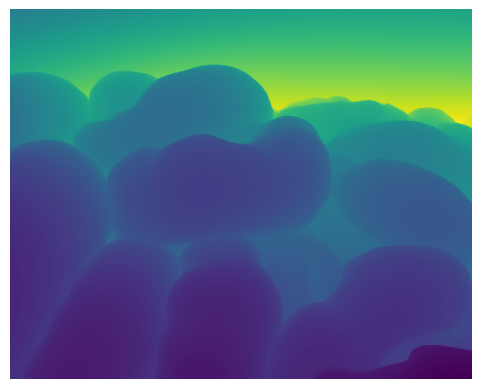

In [6]:
import matplotlib.pyplot as plt

plt.imshow(depth.cpu().numpy())
plt.axis('off')
plt.show()